# 04 — Model Results

A read-only summary of the committed results. This notebook **only reads result files and figures
already in the repository**. It loads no model, reads no flight data, retrains nothing and does not
re-run the test evaluation.

| Stage | Data used | Decision | Source files |
|---|---|---|---|
| Model selection | Fit Jan–Jul, score Aug | D-201, D-202 | `models/d201/`, `reports/results/d201_*` |
| Calibration and threshold | Sep (calibration), Oct (threshold) | D-203, D-204 | `models/d203/`, `reports/results/d203_calibration.csv` |
| Single test evaluation | Nov–Dec, once | D-205 | `reports/results/test_metrics.json` |

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

# Locate the repo root (folder containing pyproject.toml) so the notebook runs from anywhere.
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
RESULTS, FIGURES, MODELS = ROOT / "reports/results", ROOT / "reports/figures", ROOT / "models"
pd.set_option("display.width", 140)

## 1. Model selection on August (D-201, D-202)

Twelve candidate runs, all trained on January–July and scored on August. The pre-registered rule
selects the highest August PR-AUC.

In [2]:
selection = json.loads((MODELS / "d201/selection.json").read_text())
rows = []
for family in selection["candidate_results"]:
    for run in family["all_runs"]:
        p = run["parameters"]
        setting = {k: p[k] for k in ("C", "class_weight", "max_depth", "learning_rate") if k in p}
        rows.append({
            "model": run["model"],
            "setting": setting,
            "august_pr_auc": run["pr_auc"],
            "august_roc_auc": run["roc_auc"],
            "trees": run.get("effective_trees"),
        })
runs = pd.DataFrame(rows).sort_values("august_pr_auc", ascending=False).reset_index(drop=True)
print("selected model:", selection["selected_model"])
runs.round(4)

selected model: logreg


,model,setting,august_pr_auc,august_roc_auc,trees
0,logreg,"{'C': 0.01, 'class_weight': 'balanced'}",0.4007,0.6756,NaN
1,logreg,"{'C': 0.1, 'class_weight': 'balanced'}",0.4006,0.6749,NaN
2,logreg,"{'C': 1.0, 'class_weight': 'balanced'}",0.4005,0.6745,NaN
3,logreg,"{'C': 10.0, 'class_weight': 'balanced'}",0.4003,0.6743,NaN
4,logreg,"{'C': 0.1, 'class_weight': None}",0.4003,0.6739,NaN
5,logreg,"{'C': 10.0, 'class_weight': None}",0.4000,0.6733,NaN
6,logreg,"{'C': 1.0, 'class_weight': None}",0.4000,0.6733,NaN
7,logreg,"{'C': 0.01, 'class_weight': None}",0.3998,0.6742,NaN
8,xgboost,"{'max_depth': 5, 'learning_rate': 0.1}",0.3960,0.6770,16.0
9,xgboost,"{'max_depth': 3, 'learning_rate': 0.03}",0.3949,0.6732,94.0


final model: logreg {'C': 0.01, 'class_weight': 'balanced', 'max_iter': 2000}
trained on: 2013-01-01 to 2013-08-31 | selected on: 2013-08-01 to 2013-08-31


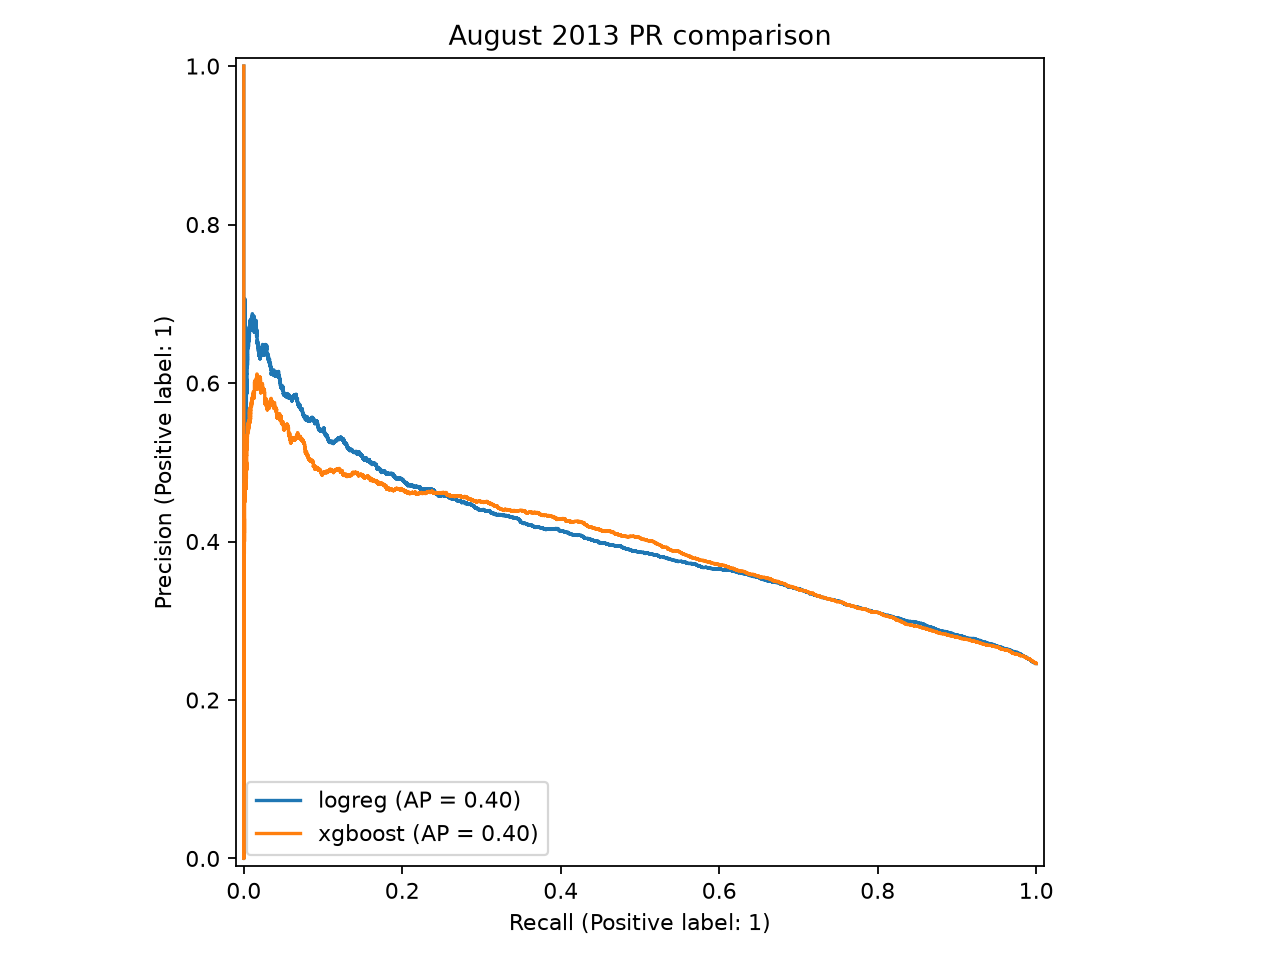

In [3]:
final = json.loads((MODELS / "d201/final_training.json").read_text())
print("final model:", final["selected_model"], final["parameters"])
print("trained on:", final["training_period"], "| selected on:", final["selection_period"])
display(Image(FIGURES / "d201_pr_comparison.png", width=520))

## 2. Feature importance (XGBoost, August; reporting only)

Gain importance from the tuned XGBoost candidate, and permutation importance on 2,000 August
flights with two repeats. These describe the model; they did not change the frozen feature set.

In [4]:
gain = pd.read_csv(RESULTS / "d201_xgboost_gain.csv").head(10)
perm = pd.read_csv(RESULTS / "d201_xgboost_permutation.csv").head(10)
display(gain.round(1))
display(perm.round(4))

,feature,gain
0,dep_hour_sin,246.3
1,hist_carrier_1d_rate,234.1
2,sched_dep_hour_frac,207.9
3,carrier_dep_bucket,206.1
4,sched_dep_origin_day,144.7
5,hist_dest_1d_rate,128.2
6,carrier_origin,121.2
7,dow,105.8
8,hist_origin_all_rate,92.2
9,is_weekend,90.9


,feature,importance_mean,importance_std
0,carrier_dep_bucket,0.0334,0.0132
1,carrier_route,0.0128,0.0001
2,sched_dep_origin_day,0.0126,0.0011
3,sched_dep_hour_frac,0.0117,0.0229
4,hist_carrier_28d_rate,0.0035,0.0013
5,carrier_dest,0.0032,0.0003
6,days_from_holiday,0.0032,0.0008
7,dow,0.0030,0.0015
8,sched_dep_carrier_origin_day,0.0021,0.0002
9,hist_carrier_1d_rate,0.0012,0.0019


## 3. Calibration and threshold (D-203, D-204)

Sigmoid calibration fitted on September; October is the out-of-sample check and is used to choose
the threshold (highest recall with precision at least 0.60).

,period,probabilities,pr_auc,roc_auc,brier,ece_10,mean_probability,delay_rate
0,september,raw,0.2457,0.6689,0.1790,0.2402,0.3774,0.1372
1,september,sigmoid,0.2457,0.6689,0.1129,0.0095,0.1372,0.1372
2,september,isotonic (comparison),0.2413,0.6707,0.1124,0.0000,0.1372,0.1372
3,october,raw,0.3248,0.6861,0.1917,0.2270,0.4026,0.1756
4,october,sigmoid,0.3248,0.6861,0.1360,0.0274,0.1483,0.1756
5,october,isotonic (comparison),0.3160,0.6856,0.1371,0.0293,0.1469,0.1756


operating point (October, precision >= 0.60): {'feasible': False, 'threshold': None, 'precision': None, 'recall': None}
rescheduling rule on October: {'flights': 28618, 'status': 'not applied: no feasible threshold'}


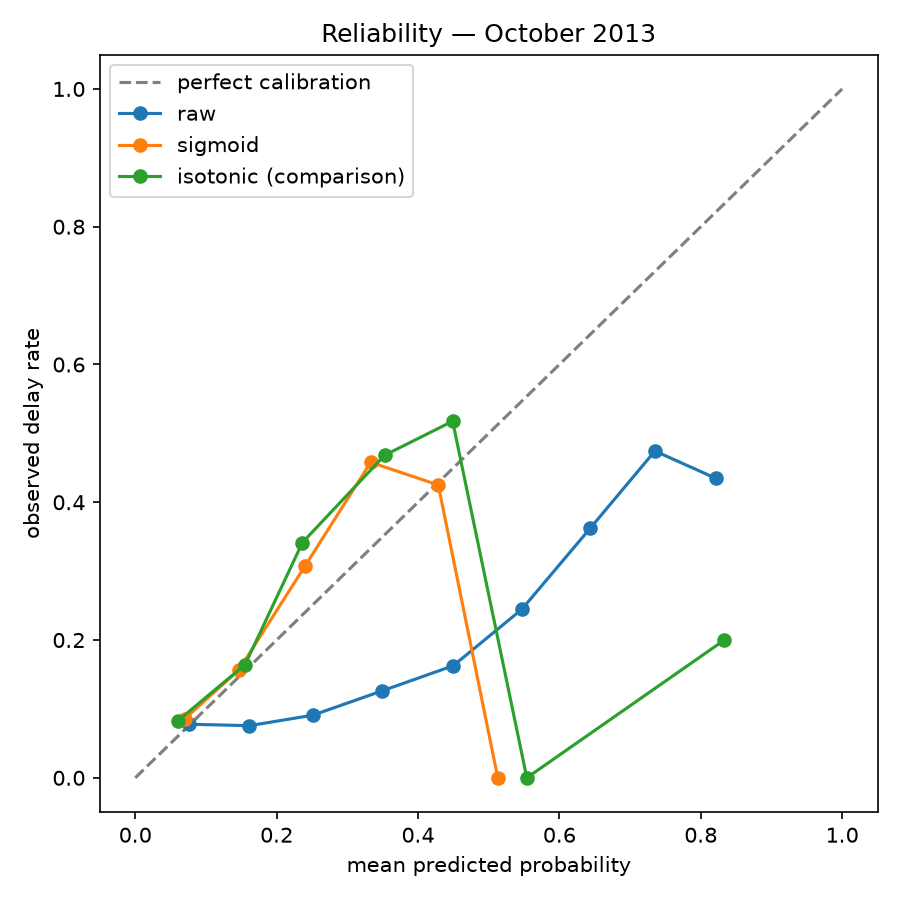

In [5]:
calibration = pd.read_csv(RESULTS / "d203_calibration.csv")
display(calibration.round(4))
op = json.loads((MODELS / "d203/operating_point.json").read_text())
print("operating point (October, precision >= {:.2f}):".format(op["min_precision"]), op["operating_point"])
print("rescheduling rule on October:", op["rescheduling_october"])
display(Image(FIGURES / "d203_reliability_october.png", width=460))

## 4. Single test evaluation (D-205)

November–December, evaluated once after the calibrated model and operating point were frozen
(tag `model-frozen`). Shown exactly as committed.

frozen commit: e559e20a98c3d86bc3dd98296016edcc3b6309e9 | test period: ['2013-11-01', '2013-12-31']


,flights,delay_rate,mean_probability,pr_auc,roc_auc,brier,ece_10
probabilities,,,,,,,
raw,53991,0.2583,0.4614,0.3979,0.664,0.2264,0.2039
sigmoid (frozen),53991,0.2583,0.1817,0.3979,0.664,0.1852,0.0768


at threshold: not available: no feasible threshold at 0.60 precision (D-204)
rescheduling rule: not applied: no feasible threshold (D-204)


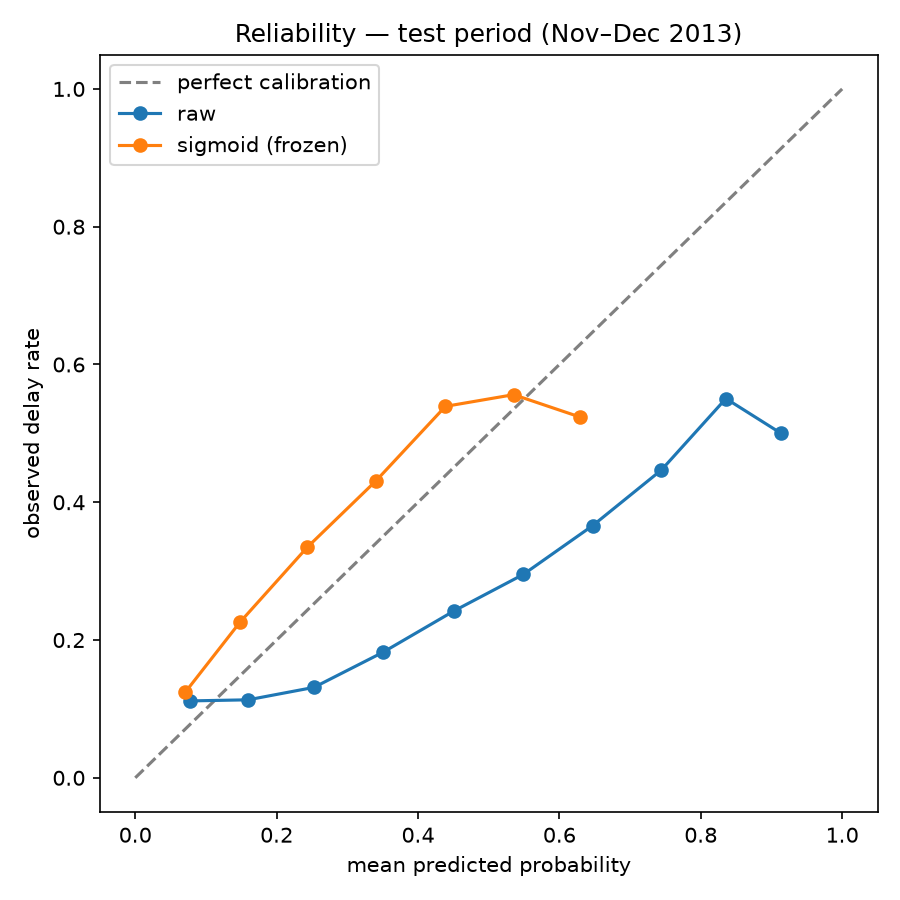

In [6]:
test = json.loads((RESULTS / "test_metrics.json").read_text())
print("frozen commit:", test["frozen_commit"], "| test period:", test["test_period"])
display(pd.DataFrame(test["metrics"]).set_index("probabilities").round(4))
print("at threshold:", test["at_threshold"])
print("rescheduling rule:", test["rescheduling_rule"])
display(Image(FIGURES / "test_reliability.png", width=460))

## Findings

- **Model choice:** Logistic Regression and XGBoost scored almost identically on August (PR-AUC
  0.4007 vs 0.3960), which suggests the limit is the information in the features rather than
  model capacity. Logistic Regression (`C = 0.01`, balanced class weights) was selected.
- **Calibration:** raw probabilities are far too high because of balanced class weights. Sigmoid
  calibration cuts October ECE from 0.227 to 0.027 without changing the ranking.
- **Threshold:** no threshold reached 60% precision on October, so none was set and the
  rescheduling rule was not applied. The target was not lowered.
- **Test:** PR-AUC 0.398 against a 0.258 delay rate (about 1.5 times random) and ROC-AUC 0.664,
  consistent with validation. Calibrated ECE is 0.077, but calibrated probabilities run low (0.18
  vs 0.26) because calibration was fitted on a calmer September.